# Día 4 — Clustering y segmentación económica

Hoy no conocemos una respuesta `y` que haya que predecir. Buscaremos **grupos de observaciones país-año** parecidas según seis indicadores, aprenderemos a describirlos y explicaremos por qué ningún grupo es una clasificación oficial de países.

## Al terminar podrás

- Distinguir clustering (explorar similitudes sin clases conocidas) de regresión y clasificación.
- Revisar unidad de observación, tipos de datos, faltantes y escalas antes de medir distancias.
- Seguir una iteración de K-Means, justificar `k` y leer tamaños, centroides, inercia y Silhouette.
- Entender cómo Ward forma grupos y qué muestra un dendrograma.
- Plantear un proyecto propio eligiendo **primero** si es regresión, clasificación o clustering.

> **Ruta presencial (3 horas):** problema/datos/escala 0–45 min; K-Means y elección de `k` 45–105; perfiles 105–145; jerárquico y proyecto 145–180. Las pruebas de estabilidad y el proyecto pueden continuarse de forma autónoma.

**Datos del ejemplo:** `datos/world_bank_latam_ml.csv`, panel de indicadores públicos del Banco Mundial ya guardado en el proyecto. No descargamos datos durante la ejecución.


## De predecir una respuesta a explorar grupos

En regresión sabíamos cuánto creció el PIB (`y` numérica). En clasificación sabíamos si un contacto terminó en `yes` o `no` (`y` categórica). **Clustering** plantea otra pregunta: «si no nos dan etiquetas de grupo, ¿qué observaciones se parecen según las variables que escogimos?». Es un método **no supervisado** porque no hay respuestas conocidas que indiquen al algoritmo a qué grupo «debería» pertenecer cada fila.

Aquí cada punto será **un país en un año**, no un país para siempre. Por ejemplo, Ecuador en 2010 y Ecuador en 2020 son dos filas que podrían caer en grupos distintos por sus indicadores de esos años. Si un algoritmo las separa, no ha descubierto que un país sea «bueno» o «malo»: solo ha propuesto similitudes conforme a las columnas, periodos y distancias que elegimos. Cambiar estas decisiones puede cambiar los grupos.

<p align="center"><img src="../material_apoyo/clustering.png" width="750"></p>


### Vocabulario antes de ejecutar el algoritmo

- **Observación:** una fila; aquí, Argentina-2005 o Ecuador-2020. Hay 140 filas originales: siete países por veinte años.
- **Variable de entrada (feature):** cada indicador numérico con el que definiremos similitud: crecimiento, inflación, desempleo, exportaciones, inversión y población. `pais`, `iso3` y `anio` identificarán filas y ayudarán a interpretar resultados, pero no deben pesar automáticamente como distancias.
- **Distancia:** número que mide diferencia entre dos filas ya preparadas; menor distancia significa mayor cercanía bajo **nuestras** variables y escala, no afinidad económica objetiva.
- **Cluster:** grupo propuesto por el algoritmo. **Centroide:** promedio de las posiciones numéricas de un grupo en K-Means; no tiene por qué coincidir con un país-año real.
- **Inercia:** suma de distancias **al cuadrado** de las filas a sus centroides; ayuda a ver qué tan compactos son los grupos, pero baja al aumentar su número.
- **Silhouette:** compara si una fila está, en promedio, más próxima a su propio grupo que a otro. Un número mayor suele indicar mejor separación geométrica; no prueba que el grupo tenga significado institucional.

Volveremos a cada palabra justo antes de usarla: no hace falta memorizar una lista antes de entender los ejemplos.


### ¿Cuándo sirve una segmentación?

Imagina tres grupos: uno con inflación baja y mayor inversión, otro con inflación alta y menor inversión, y uno formado por solo dos años extremos. Una buena descripción **menciona ambos indicadores y el tamaño de cada grupo**. Un grupo pequeño de dos filas podría señalar casos extremos, pero no permite inventar un «tipo estable de economía». También comprobaríamos si los grupos persisten al cambiar ligeramente el periodo o las variables.

Una segmentación útil responde una pregunta concreta y puede explicarse con cifras originales, no solo con colores en una figura o un Silhouette alto. Es exploratoria: no determina causalidad ni categorías oficiales.


## 1. Pregunta, fuente y unidad de observación

**Pregunta:** ¿hay *perfiles país-año* que se parezcan por crecimiento del PIB, inflación, desempleo, exportaciones, inversión y crecimiento poblacional? No tenemos una columna «perfil correcto» que enseñar al algoritmo. Seleccionamos seis indicadores para describir las condiciones de cada país en cada año; al final veremos si los grupos ayudan a formular preguntas nuevas.

Antes del modelo debemos comprobar **qué representa una fila, de qué años y países proceden los datos, qué columnas son numéricas, cuáles identifican filas y cuáles faltan**. Si mezclamos unidades o borramos años sin examinar por qué faltan, podríamos fabricar grupos que reflejan nuestras decisiones de limpieza más que un patrón económico.


In [1]:
from pathlib import Path
import os

# Configuración de esta práctica para Windows/Anaconda: ANTES de importar
# NumPy y scikit-learn, fijamos un trabajador y un hilo OpenMP.
# Evita dos avisos del entorno; no cambia los 127 casos ni sus indicadores.
os.environ["LOKY_MAX_CPU_COUNT"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram


### Antes de cargar: dos avisos de Anaconda y la ruta del CSV

En algunos Windows, `joblib` no puede consultar cuántos **núcleos físicos** tiene el equipo y continúa con los **lógicos**. En muestras pequeñas, scikit-learn también advierte que K-Means con **MKL** (librería que acelera operaciones numéricas) y muchos hilos puede tener una fuga de memoria. Son **avisos del entorno de cálculo**, no errores de los datos ni una señal de que el clustering predijo mal. Al fijar `LOKY_MAX_CPU_COUNT=1` y `OMP_NUM_THREADS=1` antes de importar las librerías, ejecutamos esta práctica pequeña con un trabajador/hilo. Puede variar el tiempo de cómputo, pero no el sentido de la pregunta ni los indicadores.

Jupyter interpreta rutas desde el directorio donde está ejecutándose. Si empezaste desde `modulo3_ml/`, el CSV está en `datos/`; si empezaste desde `modulo3_ml/notebooks/`, está en `../datos/`. La siguiente celda elige esas dos ubicaciones sin descargar nada.


In [2]:
# Una de estas dos rutas existe según el directorio de trabajo de Jupyter.
DATA_DIR = Path("datos") if Path("datos").is_dir() else Path("../datos")
archivo = DATA_DIR / "world_bank_latam_ml.csv"
print("Archivo local:", archivo.resolve())


Archivo local: C:\Users\Usuario iTC\Desktop\modulo3_ml\datos\world_bank_latam_ml.csv


In [3]:
# CSV ya guardado: la lectura no consulta al Banco Mundial.
macro = pd.read_csv(archivo)
print("Filas y columnas:", macro.shape)
macro.head()  # Cinco filas permiten revisar estructura, no generalizar a todo el panel.


Filas y columnas: (140, 9)


,iso3,pais,anio,crecimiento_pib_pct,inflacion_pct,desempleo_pct,exportaciones_pct_pib,inversion_pct_pib,crecimiento_poblacion_pct
0,ARG,Argentina,2005,8.851660,NaN,11.506,23.245877,18.888264,1.027458
1,ARG,Argentina,2006,8.047152,NaN,10.078,23.026695,18.680487,1.028248
2,ARG,Argentina,2007,9.007651,NaN,8.470,22.662750,20.099113,0.991102
3,ARG,Argentina,2008,4.057233,NaN,7.837,22.060900,19.572776,1.012889
4,ARG,Argentina,2009,-5.918525,NaN,8.645,19.560985,16.053112,1.059775


### Diccionario mínimo y procedencia

`iso3` es un código de país, `pais` su nombre y `anio` el periodo. No los convertimos en coordenadas del clustering: codificar «ARG=1, ECU=2» inventaría una distancia entre nombres, y el año mide tiempo, no automáticamente semejanza macroeconómica. Los seis indicadores están en porcentajes o porcentajes del PIB, pero no comparten la misma dispersión. Los datos públicos provienen de indicadores del Banco Mundial guardados localmente; el archivo contiene **siete países de 2005 a 2024** (140 filas país-año), no todas las economías latinoamericanas.

**Pregunta de lectura:** si un país aporta veinte años, ¿podemos llamar «grupo de países» a un cluster de filas? No: primero debemos revisar qué años de cada país quedaron juntos.


### Por qué un país puede aparecer en varios grupos

Ecuador-2008 y Ecuador-2020 son dos observaciones. Si sus cifras difieren, el algoritmo puede asignarlas a grupos distintos sin contradicción: describe **dos momentos**, no dos identidades permanentes del país. Además, las filas de años cercanos de un mismo país se parecen en instituciones y mediciones; **no son 140 economías independientes**.

`crecimiento_pib_pct` e `inflacion_pct` se leen en porcentajes; `exportaciones_pct_pib` e `inversion_pct_pib` son participaciones relativas al PIB. Un mismo número en columnas distintas no significa la misma magnitud económica. En una aplicación formal revisaríamos también cambios de definición y revisiones de las fuentes.


In [4]:
features = ["crecimiento_pib_pct", "inflacion_pct", "desempleo_pct",
            "exportaciones_pct_pib", "inversion_pct_pib", "crecimiento_poblacion_pct"]
print("Periodo:", macro.anio.min(), "–", macro.anio.max())
print("Países:", sorted(macro.pais.unique()))
print("Nulos por indicador:")
print(macro[features].isna().sum())
print("Resumen:")
print(macro[features].describe().round(2).T)


Periodo: 2005 – 2024
Países: ['Argentina', 'Brazil', 'Chile', 'Colombia', 'Ecuador', 'Mexico', 'Peru']
Nulos por indicador:
crecimiento_pib_pct           0
inflacion_pct                13
desempleo_pct                 0
exportaciones_pct_pib         0
inversion_pct_pib             0
crecimiento_poblacion_pct     0
dtype: int64
Resumen:
                           count   mean    std    min    25%    50%    75%  \
crecimiento_pib_pct        140.0   2.87   4.16 -10.93   1.13   3.06   5.84   
inflacion_pct              127.0   8.69  24.02  -0.34   2.92   3.81   5.54   
desempleo_pct              140.0   6.97   3.03   2.68   3.91   7.12   9.23   
exportaciones_pct_pib      140.0  24.58   8.91  10.71  16.43  24.04  31.33   
inversion_pct_pib          140.0  21.16   3.10  14.21  18.77  21.70  23.36   
crecimiento_poblacion_pct  140.0   1.05   0.37   0.21   0.82   1.00   1.33   

                              max  
crecimiento_pib_pct         13.42  
inflacion_pct              219.88  
desempl

### Cómo leer `describe()` y los faltantes

La tabla imprime una fila por indicador. `count` cuenta valores disponibles; `mean`, promedio; `std`, dispersión típica; `min`/`max`, extremos; y los porcentajes 25/50/75 ubican cuartiles (50 % es la mediana). Aquí inflación tiene **127 valores, no 140**: faltan **13**. Su máximo ronda **219,88 %**, muy lejos de la mediana cercana a **3,81 %**; unos pocos años de inflación extrema pueden influir mucho en medias y distancias.

No confundas «los seis nombres terminan en `_pct`» con «tienen la misma escala»: crecimiento poblacional varía mucho menos que inflación. Tampoco elimines los 13 faltantes sin preguntar **en qué país/años ocurren**: la muestra restante puede representar peor ciertos periodos.


### Nuestra decisión de limpieza para esta demostración

K-Means no puede calcular distancias si algún indicador de una fila es `NaN` (dato ausente). Para aprender el procedimiento usaremos **casos completos**: filas donde los seis indicadores están presentes. Esto es sencillo de auditar, pero reduce el panel de **140 a 127 país-año**. La conclusión se referirá a esas 127 observaciones, no automáticamente a toda América Latina ni a los veinte años completos de cada país.

Después de limpiar, pondremos los indicadores en escalas comparables. Es una decisión geométrica, **no** la afirmación de que un cambio de una desviación estándar en inflación importe económicamente igual que uno en desempleo. En el proyecto final cada equipo deberá justificar si elimina o imputa faltantes según el problema y, cuando haya Train/Validation/Test, aprender las transformaciones **solo con Train**.


### ¿Qué ejecuta `dropna(subset=features)`?

Imagina Ecuador-2010 con cinco indicadores observados e inflación ausente. Como las seis columnas participan en la distancia, `dropna` **elimina esa fila completa** del ejemplo; no pone inflación igual a cero. `copy()` conserva una tabla independiente y `reset_index` ordena sus índices. Luego `StandardScaler` toma cada columna de las 127 filas, le resta su media y la divide por su desviación estándar, de modo que cada variable preparada queda aproximadamente centrada en 0 y con dispersión 1.

Lee los dos `print`: deben decir cuántas filas quedaron y mostrar medias próximas a cero. **No confundas cero después del escalado con inflación real de 0 %**. Otras opciones —imputar o usar menos variables— requieren un análisis de sensibilidad; no las aplicamos silenciosamente.


In [5]:
# En este ejemplo exploratorio descartamos país-años incompletos (140 → 127).
analisis = macro.dropna(subset=features).copy().reset_index(drop=True)
X = analisis[features]
scaler = StandardScaler()
Xz = scaler.fit_transform(X)
print("Filas utilizables:", len(analisis), "de", len(macro))
print("Unidad de análisis: país-año; países:", analisis.pais.nunique())
print(pd.DataFrame(Xz, columns=features).agg(["mean", "std"]).round(2))


Filas utilizables: 127 de 140
Unidad de análisis: país-año; países: 7
      crecimiento_pib_pct  inflacion_pct  desempleo_pct  \
mean                  0.0           -0.0            0.0   
std                   1.0            1.0            1.0   

      exportaciones_pct_pib  inversion_pct_pib  crecimiento_poblacion_pct  
mean                   -0.0                0.0                       -0.0  
std                     1.0                1.0                        1.0  


## Distancias: por qué escalamos antes de agrupar

Supón dos filas que difieren **1 000 dólares** en una variable y **1 punto porcentual** en otra. Sin preparar los números, la distancia estará dominada por 1 000 aunque ese indicador no sea el más importante para la pregunta. En el ejemplo siguiente la primera columna sería PIB por persona **solo como ilustración**; ese PIB per cápita no es una de las seis columnas del clustering.

`StandardScaler` transforma cada valor en $z=(x-\mu)/s$, donde $\mu$ es la media de esa columna y $s$ su desviación estándar. Así las diferencias se comparan en unidades de dispersión, no en dólares frente a porcentajes. K-Means y Ward usan aquí **distancia euclidiana** (distancia en línea recta) sobre los seis indicadores escalados. Euclidiana es una elección del método utilizado, no la única manera posible de definir semejanza; cambiar la distancia puede cambiar los perfiles.

En esta demostración **descriptiva** se exploran todas las filas completas juntas. En el proyecto, si se separa Train/Validation/Test para estudiar estabilidad fuera de la muestra, la media y desviación deberán aprenderse solo en Train y aplicarse a las otras partes, sin recalcularlas allí.


In [6]:
# Ilustración: la unidad de medida puede dominar la distancia
pib_a, pib_b = 42000, 43000       # dólares por persona
tasa_a, tasa_b = 4.0, 5.0         # puntos porcentuales
diferencia_pib = abs(pib_a - pib_b)
diferencia_tasa = abs(tasa_a - tasa_b)
print("Diferencia cruda en PIB:", diferencia_pib)
print("Diferencia cruda en tasa:", diferencia_tasa)
print("Sin estandarizar, el primer número dominaría la suma de distancias.")


Diferencia cruda en PIB: 1000
Diferencia cruda en tasa: 1.0
Sin estandarizar, el primer número dominaría la suma de distancias.


### Qué demuestra y qué no demuestra el ejemplo de unidades

El código muestra una diferencia cruda de 1 000 frente a 1. Eso basta para sospechar que medir distancias sin preparar variables puede ignorar la segunda. **No** demuestra que una desviación estándar de dos indicadores tenga idéntico valor económico ni que escalarlos haga verdaderos los clusters. El escalado resuelve una cuestión de geometría; la elección de indicadores y su interpretación siguen siendo decisiones del analista.


## 2. K-Means: buscar centros y asignar filas

K-Means intenta representar las filas mediante **`k` grupos**. Para cada grupo calcula un **centroide** (posición promedio) y asigna cada país-año al centroide más cercano. «Means» significa **medias**: los centros se recalculan promediando los puntos de cada grupo. La letra `k` indica cuántos grupos pedimos; no aparece una respuesta oficial que nos diga el número correcto.

Antes de usar las 127 filas, seguiremos una sola vuelta con **cuatro puntos inventados** para entender qué calcula el algoritmo. Después probaremos distintos valores de `k` y veremos si producen grupos interpretables.


### Una iteración explicada sin una caja negra

Empieza con dos centros provisionales, A y B. **Paso 1:** mide la distancia de cada punto a ambos y asígnalo al más cercano. **Paso 2:** promedia las coordenadas de los puntos asignados a A para mover el centro A; haz lo mismo con B. **Paso 3:** vuelve a asignar con los centros nuevos. El algoritmo repite asignar y promediar hasta estabilizarse o llegar a su límite de iteraciones.

La **inercia** suma las distancias al cuadrado de cada fila a su centro asignado; K-Means intenta reducirla. Una distancia al cuadrado hace que puntos muy lejanos pesen bastante. Por eso un año extremo de inflación podría formar un grupo pequeño: habrá que interpretarlo con cautela en vez de llamarlo automáticamente «régimen».


In [7]:
# Una vuelta manual: asignar puntos y recalcular centroides
toy = np.array([[1., 1.], [1., 2.], [5., 5.], [6., 5.]])
centros_iniciales = np.array([[1., 1.], [5., 5.]])
dist = np.linalg.norm(toy[:, None, :] - centros_iniciales[None, :, :], axis=2)
asignacion = dist.argmin(axis=1)
centros_nuevos = np.vstack([toy[asignacion == k].mean(axis=0) for k in range(2)])
print("Distancias punto-centroide:", dist.round(2), sep="\n")
print("Asignación:", asignacion)
print("Centroides recalculados:", centros_nuevos, sep="\n")


Distancias punto-centroide:
[[0.   5.66]
 [1.   5.  ]
 [5.66 0.  ]
 [6.4  1.  ]]
Asignación: [0 0 1 1]
Centroides recalculados:
[[1.  1.5]
 [5.5 5. ]]


### Comprueba la vuelta manual

El juguete contiene cuatro puntos: dos cerca de (1, 1) y dos cerca de (5, 5). `np.linalg.norm` calcula la distancia de cada punto a los dos centros iniciales; `argmin` elige el menor. Después `mean(axis=0)` promedia cada coordenada de los miembros de un grupo. Predice antes de ejecutar: ¿deberían los centros nuevos seguir cerca de los dos conjuntos? Esta celda enseña **una** iteración, no los grupos reales de países.


### Por qué inicialización y semilla pueden importar

K-Means necesita centros iniciales. Según dónde empiecen, puede llegar a distintas soluciones **locales**: mejora los centros desde su punto de partida, pero no prueba haber encontrado la mejor partición posible. `n_init=20` prueba veinte inicializaciones y conserva la mejor según inercia; `random_state=42` hace repetible el sorteo. Repetible no significa verdadero. Si cambiar semillas o quitar una variable cambia mucho los perfiles, informa que son frágiles.


In [8]:
# Probamos de 2 a 6 grupos sobre LAS MISMAS seis columnas escaladas.
ks = range(2, 7)
medidas = []
for k in ks:
    m = KMeans(n_clusters=k, n_init=20, random_state=42).fit(Xz)
    medidas.append({"k": k, "inercia": m.inertia_, "silhouette": silhouette_score(Xz, m.labels_)})
tabla_k = pd.DataFrame(medidas)
tabla_k.round(3)


,k,inercia,silhouette
0,2,536.781,0.317
1,3,433.996,0.326
2,4,365.717,0.257
3,5,303.685,0.268
4,6,268.173,0.283


### Dos ayudas para elegir `k`: codo y Silhouette

Probamos `k=2,3,4,5,6`. La **inercia** siempre tiende a bajar cuando damos más centros: es más fácil colocar cada punto cerca de alguno. Si escogiéramos únicamente la inercia menor, acabaríamos prefiriendo demasiados grupos. En el **gráfico del codo** buscamos el punto a partir del cual agregar un grupo mejora cada vez menos; a veces no hay codo claro.

**Silhouette** pregunta para cada fila si está más próxima, en promedio, a su propio grupo que al otro grupo más cercano. Llama `a` a la distancia media a compañeros y `b` a la distancia media al grupo alternativo; $s=(b-a)/\max(a,b)$. Cerca de **1** sugiere buena separación, cerca de **0** indica frontera ambigua y un valor **negativo** indica que la fila podría encajar mejor fuera de su grupo. El promedio puede ocultar un grupo diminuto o filas mal asignadas; no equivale a «precisión» porque **no hay etiquetas reales**.


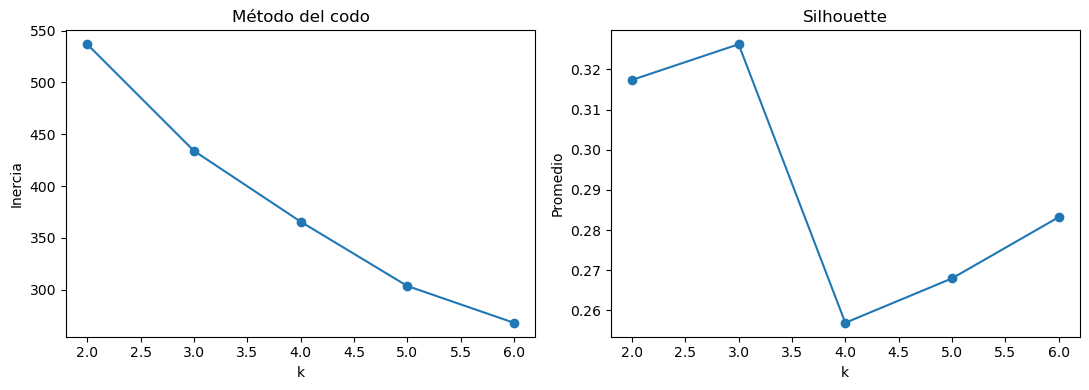

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(tabla_k.k, tabla_k.inercia, marker="o"); ax[0].set(title="Método del codo", xlabel="k", ylabel="Inercia")
ax[1].plot(tabla_k.k, tabla_k.silhouette, marker="o"); ax[1].set(title="Silhouette", xlabel="k", ylabel="Promedio")
plt.tight_layout()


### Cómo leer los dos gráficos

En el panel izquierdo (`inercia`), compara cuánto baja la curva al pasar de `k=2` a 3, de 3 a 4, etc. Busca rendimientos decrecientes, **no** que la curva llegue a cero. En el derecho (`Silhouette`), compara qué `k` separa mejor los grupos bajo la distancia elegida. Antes de decidir, revisa también el número de filas por grupo: un promedio atractivo puede depender de unas pocas observaciones extremas.

El rango 2–6 es una exploración pequeña, apropiada para la clase. Ningún gráfico dice por sí solo qué perfil tiene sentido económico; esa pregunta se responde más adelante con los centroides y los años/países de cada grupo.


### No elijas el número de grupos automáticamente

Si la inercia mejora al pasar a cuatro grupos pero uno tiene solo dos años con inflación excepcional, quizá sea útil **describir esos años como casos extremos**, no proponer cuatro «tipos de país». Si Silhouette favorece dos grupos y los perfiles de tres resultan más claros, documenta el desacuerdo. Aquí `k=3` servirá de demostración reproducible; el ejercicio autónomo permite defender otro `k` con evidencia.


### Regla práctica y transparente para `k`

Anota: (1) dónde la inercia empieza a mejorar menos; (2) qué valores de `k` muestran mayor Silhouette; (3) cuántas filas habría en cada grupo; (4) qué pregunta económica ayudaría a responder cada perfil. Si ninguno produce grupos razonables, «no encontré una separación convincente» es una conclusión válida. No escogemos `k=3` porque el algoritmo haya descubierto exactamente tres regímenes: lo fijamos para practicar cómo describirlos.


### Toma una decisión antes de leer los perfiles

Revisa la tabla de `k=2..6` y propone uno con **dos razones cuantitativas** (codo, Silhouette o tamaños). Luego mira los perfiles en escala original: si no responden a tu pregunta, puedes reconsiderar `k`, pero registra esa revisión; no afirmes que el primer número surgió de una prueba objetiva. Una alternativa es mostrar dos soluciones para ilustrar que la interpretación depende de la representación y del criterio elegido.


## 3. Leer lo que significan los grupos

Usaremos **`k=3` únicamente como ejemplo**. El modelo escribirá en cada fila un número de cluster (0, 1 o 2), contará cuántos países-años contiene cada grupo y mostrará su centroide. Los números son etiquetas arbitrarias, **no un ranking**: 2 no es «mejor» que 0. Para entender el resultado hay que volver a las unidades originales y a los países/años concretos.


### ¿Por qué ajustamos K-Means de nuevo?

El bucle anterior ensayó distintos valores de `k` y guardó solo inercia/Silhouette en una tabla. Ahora `KMeans(n_clusters=3, n_init=30, random_state=42)` ajusta un modelo de tres grupos y conserva sus **asignaciones**. `fit_predict(Xz)` devuelve un número de grupo por cada una de las 127 filas preparadas. `inverse_transform` deshace el escalado **solo para leer los centroides** en porcentajes comprensibles; los grupos se calcularon con los valores escalados.


In [10]:
# k=3 es una elección didáctica; no representa tres clases verdaderas.
k_elegido = 3
kmeans = KMeans(n_clusters=k_elegido, n_init=30, random_state=42)
analisis["cluster"] = kmeans.fit_predict(Xz)
centros = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features)
centros.index.name = "cluster"
print("Tamaño de grupos:")
print(analisis.cluster.value_counts().sort_index())
print("Perfiles (centroides en unidades originales):")
print(centros.round(2))


Tamaño de grupos:
cluster
0    77
1    48
2     2
Name: count, dtype: int64
Perfiles (centroides en unidades originales):
         crecimiento_pib_pct  inflacion_pct  desempleo_pct  \
cluster                                                      
0                       3.51           3.69           4.95   
1                       1.93           9.72           9.89   
2                      -1.60         176.69           6.64   

         exportaciones_pct_pib  inversion_pct_pib  crecimiento_poblacion_pct  
cluster                                                                       
0                        31.25              22.87                       1.15  
1                        16.23              19.44                       0.93  
2                        14.04              17.61                       0.32  


### Antes de dar nombres: mira los tamaños

La salida de esta muestra muestra **77, 48 y 2 filas** en los clusters 0, 1 y 2. El grupo 2 es especialmente pequeño: su inflación promedio puede representar un par de años extremos y **no** una categoría estable de países. Un centroide promedia a sus miembros; si solo tiene dos, una observación diferente cambiaría mucho el perfil.

Describe los grupos con los indicadores observados —por ejemplo «mayor inflación en estas dos observaciones»— y evita etiquetas como «buenas economías» o afirmaciones causales. Los identificadores 0, 1 y 2 podrían cambiar de nombre al reajustar sin que cambien sus miembros.


### Del centroide a una frase económica verificable

Un centroide calculado tras `StandardScaler` no se leería como porcentaje real hasta aplicar `scaler.inverse_transform`. Ahora la tabla vuelve a mostrar, por ejemplo, inflación y desempleo en sus unidades originales. Compara **la misma columna entre grupos** y con el resumen inicial. Aquí un cluster de solo dos filas tiene inflación media alrededor de **176,69 %**, frente a valores mucho menores en los otros; describe ese hecho junto con su tamaño, no como promedio de todo un país.

Una frase prudente sería: «Entre las observaciones completas, este grupo de dos país-años presenta inflación excepcionalmente alta; es sensible a valores extremos y no demuestra un régimen persistente». El centroide podría no coincidir con ninguna fila concreta.


### El tamaño y la dispersión completan el promedio

Un centroide no indica si todos sus miembros se parecen mucho o si combina años distintos. Para un grupo de 77 filas, examina rango y ejemplos cercanos/lejanos al centro; para el de dos, identifica exactamente **qué país-año son** antes de generalizar. Un grupo grande no implica relevancia institucional y uno pequeño no confirma una anomalía; ambos necesitan contexto y sensibilidad a los indicadores escogidos.


### 3.1 ¿Dónde y cuándo aparecen los perfiles?

La tabla por país muestra **proporciones de sus años utilizables** en cada cluster, no probabilidades futuras. La tabla por periodo pregunta si las asignaciones se concentraron, por ejemplo, entre 2020 y 2024. Un país puede aparecer en varios grupos porque cambian sus años. Primero mira cuántas filas aportó y después interpreta los porcentajes; una fracción de 50 % podría basarse en solo dos años.


In [11]:
print('Distribución de clusters dentro de cada país:')
print(pd.crosstab(analisis.pais, analisis.cluster, normalize='index').round(2))

analisis['periodo'] = pd.cut(analisis.anio, bins=[2004, 2009, 2014, 2019, 2024],
                            labels=['2005–2009', '2010–2014', '2015–2019', '2020–2024'])
print('Distribución por periodo:')
print(pd.crosstab(analisis.periodo, analisis.cluster, normalize='index').round(2))

Distribución de clusters dentro de cada país:
cluster       0     1     2
pais                       
Argentina  0.00  0.71  0.29
Brazil     0.00  1.00  0.00
Chile      0.95  0.05  0.00
Colombia   0.00  1.00  0.00
Ecuador    0.95  0.05  0.00
Mexico     1.00  0.00  0.00
Peru       0.95  0.05  0.00
Distribución por periodo:
cluster       0     1     2
periodo                    
2005–2009  0.67  0.33  0.00
2010–2014  0.67  0.33  0.00
2015–2019  0.62  0.38  0.00
2020–2024  0.49  0.46  0.06


### No conviertas un patrón en una explicación causal

Si el grupo de inflación extrema aparece en un periodo concreto, eso permite investigar qué filas y condiciones coinciden con él; **no demuestra** que el año o una variable haya causado la pertenencia al grupo. Los porcentajes de la tabla están condicionados por las 127 filas completas: un país que perdió años por faltantes está menos representado. Menciona al menos un patrón descriptivo, su cantidad de observaciones y una explicación alternativa plausible que el clustering no puede resolver.


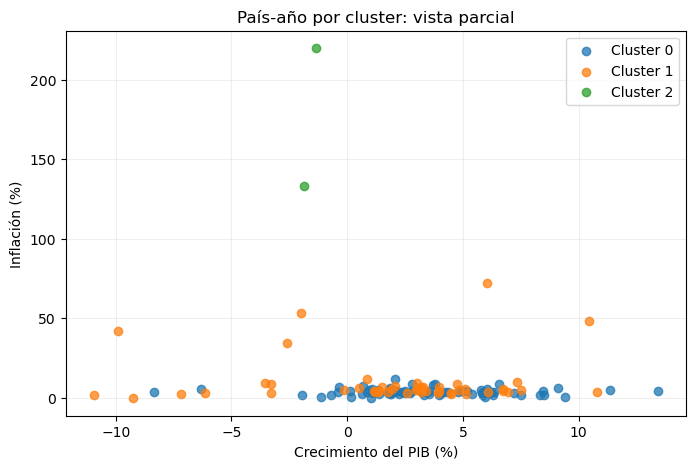

In [12]:
# Proyección descriptiva: dos indicadores seleccionados, NO son el espacio completo de seis dimensiones.
fig, ax = plt.subplots(figsize=(8, 5))
for c, grupo in analisis.groupby("cluster"):
    ax.scatter(grupo["crecimiento_pib_pct"], grupo["inflacion_pct"], label=f"Cluster {c}", alpha=.75)
ax.set(xlabel="Crecimiento del PIB (%)", ylabel="Inflación (%)", title="País-año por cluster: vista parcial")
ax.legend(); ax.grid(alpha=.2)


### ¿Qué vemos en el gráfico de puntos?

Cada punto es un país-año; su posición horizontal es crecimiento y la vertical inflación, y el color representa el cluster asignado usando **seis indicadores escalados**. Si dos colores se mezclan en este plano, no significa que K-Means ignoró sus otras cuatro variables. Si parecen separados, el gráfico tampoco prueba que la segmentación sea robusta. Revisa la tabla de centroides y los tamaños; el punto de inflación extrema puede estirar el eje y esconder diferencias entre los demás.


### Una vista 2D no es todo el espacio de seis variables

El scatter solo dibuja crecimiento e inflación porque son familiares, mientras K-Means midió similitud también con desempleo, exportaciones, inversión y población. Dos puntos superpuestos podrían diferir mucho en inversión; dos separados en el plano podrían parecerse en los otros cuatro indicadores. La figura ayuda a **comunicar** parte del patrón, no valida automáticamente los grupos. En el Día 5 estudiaremos PCA como otra forma de proyectar muchas variables a dos ejes, con pérdida de información explícita.


## 4. Agrupación jerárquica: construir una historia de fusiones

K-Means comienza con un número `k` de centros. El método **jerárquico aglomerativo** comienza al revés: cada país-año es un grupo separado y luego va **uniendo** los grupos más parecidos, paso a paso, hasta formar uno solo. Un **dendrograma** dibuja esa secuencia como un árbol de ramas: une primero observaciones próximas y muestra a qué altura se fusionan grupos más diferentes.

Usaremos **Ward**, una regla que prefiere fusiones que aumenten lo menos posible la variación interna de los grupos. Aquí funciona sobre los mismos seis números escalados y con distancia euclidiana. No es el árbol de decisión supervisado del Día 3: sus ramas muestran fusiones de observaciones, **no preguntas para predecir `yes/no`**.


### ¿Qué regla decide qué grupos se unen?

La palabra **linkage** nombra esa regla de unión. Una posibilidad sería unir grupos según su par de puntos más cercanos (*single*), otra usar los más lejanos (*complete*), otra promediar distancias (*average*). **Ward** elige la unión que menos incrementa la dispersión interna de los grupos. No hay una regla universalmente mejor; hoy usamos Ward para comparar con K-Means, que también favorece perfiles compactos.

`linkage(Xz, method="ward")` construye todas las fusiones y `dendrogram(...)` las dibuja; las etiquetas de cada hoja muestran el país y año para recordar qué representa cada punto.


### Diferencia entre K-Means y Ward

K-Means recibe `k=3` antes de empezar y desplaza tres centroides mediante medias. Ward fusiona observaciones desde abajo y permite dibujar **dónde** se unieron antes de decidir un corte de tres grupos. Pueden coincidir bastante porque ambos usan las mismas seis variables escaladas y prefieren grupos relativamente compactos; esa coincidencia no demostraría que los grupos son «verdaderos». No compares solo colores o números arbitrarios: compara **qué país-años comparten** y sus perfiles.


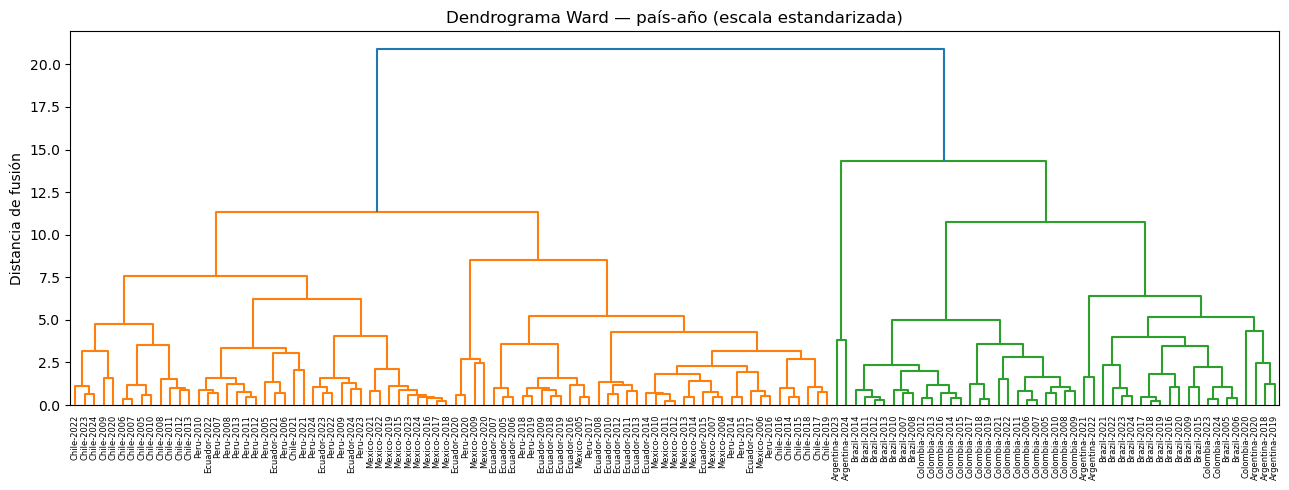

In [13]:
# Ward fusiona observaciones; el dendrograma NO es un árbol de predicción.
Z = linkage(Xz, method="ward")
plt.figure(figsize=(13, 5))
dendrogram(Z, labels=(analisis.pais + "-" + analisis.anio.astype(str)).tolist(), leaf_rotation=90, leaf_font_size=6)
plt.title("Dendrograma Ward — país-año (escala estandarizada)")
plt.ylabel("Distancia de fusión"); plt.tight_layout()


### Leer un dendrograma sin perderse en las etiquetas

Cada hoja en la base representa un país-año. Dos ramas que se unen **a poca altura** corresponden a grupos cercanos bajo Ward; una unión muy arriba representa un mayor aumento de dispersión. Imagina dibujar una línea horizontal que corte varias ramas: cada conjunto de hojas conectado **debajo** de la línea sería un grupo. Con 127 hojas es normal que los nombres se amontonen; mira primero la estructura general y luego usa tablas para ver sus miembros.

La altura **no es probabilidad ni significancia estadística**. El gráfico ayuda a explorar posibles cortes, pero no sustituye describir tamaños y centroides.


### Altura de fusión y número de grupos

Si varias uniones pequeñas ocurren abajo y luego aparece un salto vertical grande, cortar justo **antes de ese salto** mantiene separados grupos que Ward uniría con mayor costo. Es una pista visual, no una fórmula para hallar el número «correcto». En un dendrograma con tantas hojas, elegir una altura para obtener tres grupos y después contarlos suele ser más informativo que intentar leer cada nombre directamente.


### Proponer un corte con cautela

Escoge provisionalmente una altura que conserve ramas distinguibles. Pregunta: ¿cuántas filas tiene cada rama?, ¿puedo describir sus indicadores en unidades originales?, ¿cambia todo si desplazo un poco la línea? Si una pequeña variación transforma por completo los perfiles, la separación es frágil. La altura del eje pertenece a la geometría del método, no a una «probabilidad de estar juntos».


In [14]:
# Los números 0/1/2 de K-Means y Ward son etiquetas arbitrarias.
jer = AgglomerativeClustering(n_clusters=k_elegido, linkage="ward")
analisis["cluster_jerarquico"] = jer.fit_predict(Xz)
print(pd.crosstab(analisis.cluster, analisis.cluster_jerarquico, normalize="index").round(2))


cluster_jerarquico     0     1    2
cluster                            
0                   1.00  0.00  0.0
1                   0.06  0.94  0.0
2                   0.00  0.00  1.0


### Comparar miembros, no los números 0, 1 y 2

Después de ajustar Ward con tres grupos, la tabla cruzada cuenta cuánto se solapan sus asignaciones con las de K-Means. **Cluster 0** de un método no tiene por qué representar el **0** del otro: esos números son nombres arbitrarios. Observa qué proporción de cada fila queda en una columna, incluso si las etiquetas cambiaron de número.

La siguiente celda calcula **ARI** (*Adjusted Rand Index*), un índice que compara si dos métodos colocan **pares de observaciones** juntos o separados, corrigiendo parte del acuerdo esperado por azar. Vale **1** cuando las particiones coinciden, cerca de **0** cuando el acuerdo no supera lo esperado por azar y puede ser negativo. Tampoco ARI valida una interpretación económica.


In [15]:
ari = adjusted_rand_score(analisis.cluster, analisis.cluster_jerarquico)
print("Adjusted Rand Index, K-Means vs Ward:", round(ari, 3))


Adjusted Rand Index, K-Means vs Ward: 0.908


### ¿Qué significa el ARI observado?

En esta ejecución, ARI ronda **0,908**: K-Means y Ward colocaron de forma parecida muchos pares de país-años. Eso **no** demuestra que sus clusters sean verdaderos, causales u oficiales: ambos métodos recibieron las mismas variables, limpieza y escala, y por ello comparten posibles sesgos.

Para estudiar **estabilidad**, repite K-Means con otra semilla, quita un indicador o cambia un periodo y compara si se sostienen tamaños y perfiles. La inflación extrema y el cluster de dos casos merecen especial revisión. Un algoritmo que entrega siempre un número de grupo no garantiza que exista una segmentación útil.


### Cierre de la comparación de métodos

Con una tabla puedes responder: «¿qué filas quedaron juntas en ambos métodos?»; con centroides, «¿en qué indicadores se parecen?»; con ARI, «¿cuánto se parecen las dos particiones?». Son tres preguntas diferentes. Para concluir, di qué muestra cada evidencia, qué observaciones son extremas y qué cambia al variar una decisión de preparación. Evita presentar el grupo 0 como un tipo permanente de país.


## 5. Taller guiado de segmentación económica — preparación para el proyecto

Este taller practica el método con el panel de la clase y **no suma una nota adicional**: (1) explica que una fila es país-año y documenta fuente/periodo/faltantes; (2) muestra por qué escalas las seis variables; (3) compara `k=2..6` con inercia y Silhouette; (4) elige `k`, presenta tamaños y centroides en escala original; (5) contrasta K-Means con Ward; (6) escribe dos hallazgos descriptivos y tres límites. La **Tarea 1 de 20 puntos** comienza a continuación con la pregunta y el dataset que cada equipo elija para su proyecto.

**Entrega:** notebook reproducible con figuras legibles y síntesis de hasta 200 palabras. No llames «validación por Accuracy» a Silhouette: clustering no dispone de clases `yes/no` correctas para calcular esa métrica.


## Proyecto integrador: cinco preguntas posibles, cinco archivos locales

**El primer paso NO es escoger un algoritmo.** Escribe la pregunta, identifica qué representa **una fila** y cuál sería la respuesta buscada. Si quieres predecir **una cantidad**, es **regresión**; si quieres predecir **una categoría conocida**, es **clasificación**; si no hay respuesta/etiqueta y quieres explorar semejanzas, es **clustering**. En la ficha explica **por qué** tu opción pertenece a ese tipo. Todos los CSV siguientes ya están en `datos/`; no hace falta descargarlos durante clase.

| Opción y archivo | Pregunta investigable y tipo esperado | Una fila / respuesta o variables | Advertencia inicial |
| --- | --- | --- | --- |
| **A.** `actividad_economica_reto.csv` | ¿Podemos estimar `crecimiento_actividad_pct` de una región y sector? **Regresión**: el resultado es un porcentaje continuo. | Un registro **fecha–región–sector**; 193 filas sintéticas didácticas, 2022–2025. `region` y `sector` son cualitativas; `indice_confianza` tiene faltantes. | Comparar un promedio de Train con una regresión y un árbol; dividir por **fecha**, no mezclar meses futuros. Definir qué predictores se conocen al hacer la estimación. |
| **B.** `bank_marketing_uci.csv` | Antes de la llamada, ¿qué contactos históricos se parecen a quienes terminaron en `yes`? **Clasificación binaria**: `y` vale `yes/no`. | Un contacto de una campaña bancaria portuguesa; 41 188 filas públicas de UCI; ocupación, educación, mes y otras categorías. | No usar `duration` (solo se conoce después). Estratificar clases y comparar baseline, árbol y otro clasificador mediante matriz de confusión, Precision/Recall/F1. |
| **C.** `telco_churn_fallback.csv` | ¿Qué clientes del ejemplo abandonaron el servicio (`Churn=Yes`)? **Clasificación binaria**: abandono `Yes/No`. | Un cliente, **4 500 filas sintéticas**. `Contract`, `InternetService` y `PaperlessBilling` son categorías; `customerID` es identificador. | Descartar ID y `tipo_dato`, revisar posible desbalance y codificar categorías dentro del Pipeline. No presentar el dataset como empresa real. |
| **D.** `world_bank_latam_ml.csv` | ¿Qué **país-años** comparten perfiles macroeconómicos? **Clustering**: no hay columna con grupo «correcto». | 140 país-años públicos (siete países, 2005–2024); seis indicadores numéricos. `pais`, `iso3`, `anio` sirven para describir las filas, no para darles un orden artificial. | Hay **13 inflaciones faltantes** y valores extremos; comparar perfiles/tamaños/estabilidad. No inventar Accuracy ni usar crecimiento como `y` si elegiste clustering. |
| **E.** `macro_mensual_demo.csv` | Con información disponible en el mes `t`, ¿cuál será `indice_actividad` en `t+1`? **Regresión temporal**: la respuesta futura es un número. | Una fecha mensual, **144 meses sintéticos**, 2014–2025. Crear rezagos y baselines de persistencia/estacionalidad. | Dividir **cronológicamente**; nunca usar el valor de `t+1` como predictor de sí mismo ni llamar oficiales a los valores simulados. |

Estas son **cinco propuestas independientes**: cada equipo escoge una y puede afinar su pregunta antes de modelar. La clasificación de la opción está sugerida para orientar, pero el equipo debe defenderla: si cambia la pregunta y el target, podría cambiar el tipo de problema.

### Guion obligatorio del proyecto, paso a paso

1. **Plantea problema y tipo.** Escribe qué decisión se apoyaría, qué representa una fila, qué se intenta predecir (`y`) o, en clustering, por qué **no existe `y` de grupo**. Indica la población, periodo, procedencia y si los datos son **públicos observados o sintéticos**. Señala cuándo estarán disponibles los predictores para evitar pistas del futuro.
2. **Lee y explica el dataset antes de transformarlo.** Enseña `shape`, `head`, nombres, `dtypes`, diccionario con unidad de cada columna, recuento de clases si las hay, nulos, duplicados, rangos y categorías como `unknown`. Distingue **cuantitativas** (números con unidades), **cualitativas** (región, sector, contrato), **fechas**, **identificadores**, variable objetivo y columnas constantes de metadatos como `tipo_dato`. Documenta qué filas/casos eliminarías y por qué.
3. **Haz exploración visual con propósito.** Incluye al menos **tres** gráficos legibles, con título, ejes y lectura: distribución del target o tamaños de clase; histograma/caja de una variable y sus extremos; dispersión entre dos numéricas, evolución temporal o barras de una categoría frente a la respuesta. Para clustering, añade tamaño/perfil de grupos y una vista bidimensional **sin afirmar que muestra todas las dimensiones**. Un gráfico no prueba causalidad.
4. **Divide Train, Validation y Test según la pregunta.** En clasificación, haz un split estratificado si los contactos/clientes son intercambiables y reserva Test hasta el final. En series temporales o datos por fecha, usa **orden cronológico**; si preguntas por países nunca vistos, separa países completos. En regresión observa también dependencias por región/sector o fecha. **En clustering**, divide igualmente las filas para estudiar estabilidad: aprende limpieza, escala y centros K-Means en Train; usa Validation para elegir `k` y describir nuevas asignaciones, y Test retenido para comprobar perfiles/estabilidad sin llamarlo «Accuracy». Ward no dispone de `.predict()` para nuevas filas: si eliges Ward, explica otra evaluación de estabilidad y no inventes predicciones supervisadas.
5. **Limpia y convierte categorías sin fuga.** Puedes identificar las columnas cualitativas **desde el comienzo**, pero **primero divide** los datos. Después ajusta imputación, escalado y `OneHotEncoder(handle_unknown="ignore")` **solo en Train dentro de un Pipeline/ColumnTransformer**; aplica lo aprendido a Validation y Test. Así `region`, `sector`, `job` o `Contract` pasan a columnas numéricas 0/1 sin asignar un orden falso como `Costa=1`, `Sierra=2`. No codifiques `customerID`, `pais` o `tipo_dato` automáticamente como si representaran magnitudes; en clustering usa solo categorías sustantivas si justificas una representación y una distancia apropiadas.
6. **Modela y compara con una referencia.** Regresión: predicción de media/persistencia como baseline y al menos un modelo; MAE/RMSE/R² en unidades. Clasificación: mayoría como baseline, matriz de confusión y Precision/Recall/F1 de la clase de interés junto a Accuracy. Clustering: varios `k`, inercia/Silhouette, tamaños, centroides en unidades originales y sensibilidad a variables/extremos. Elige con Train/Validation, **no con Test**.
7. **Cierra y comunica.** Una vez fijado el procedimiento, evalúa Test una sola vez (o la estabilidad final en clustering), explica errores y límites, incluye una figura y una conclusión de 150–250 palabras para alguien no técnico. Si el resultado no supera al baseline o los clusters son frágiles, dilo: también es una conclusión válida.

**Evaluación del mismo proyecto, sin tareas duplicadas:** Tarea 1 (Día 4, 20 puntos) = planteamiento y auditoría inicial; Tarea 2 (Día 5, 20 puntos) = exploración, limpieza, partición y transformación; Tarea 3 (Día 6, 20 puntos) = referencia, modelos y validación; práctica final (Día 7, 40 puntos) = comprobación final, notebook integrado y **síntesis escrita, sin exposición oral**. Diagnóstica del Día 1 = 0 puntos; los laboratorios de los días 2–3 son práctica guiada sin nota independiente. **Total: 60 formativa + 40 final = 100.** Los instrumentos y rúbricas están en [`INSTRUMENTOS_EVALUACION_MODULO3.md`](../INSTRUMENTOS_EVALUACION_MODULO3.md). No subir datos institucionales o confidenciales a servicios externos.


### Proyecto integrador — Tarea 1: pregunta y auditoría inicial (20 puntos)

**Práctica guiada, entrega al terminar el Día 4.** Elige **uno** de los cinco archivos locales de la tabla anterior. En una ficha breve y las primeras celdas de tu propio notebook: (1) plantea una pregunta concreta y justifica si la respuesta es numérica (regresión), categórica (clasificación) o si no hay etiqueta y buscas grupos (clustering); (2) indica fuente, carácter público/sintético, periodo, unidad de observación y objetivo si existe; (3) carga el CSV y revisa tamaño, columnas, tipos numéricos/categóricos, fechas, identificadores, faltantes, duplicados y valores especiales; (4) presenta un primer gráfico con una frase que lo interprete y propone otros dos; (5) bosqueja cómo dividirás Train/Validation/Test y qué referencia o criterio de grupos usarás. **Todavía no se evalúa el rendimiento final ni se consulta Test.**

**Evidencia:** ficha más notebook inicial ejecutable. Rúbrica de 20 puntos en [`INSTRUMENTOS_EVALUACION_MODULO3.md`](../INSTRUMENTOS_EVALUACION_MODULO3.md). El análisis completo de los grupos de esta clase es un ejemplo guiado; no se califica por separado de esta tarea.


### Ejemplo guiado: de categorías de clientes a columnas numéricas

Supón que elegiste la **opción C**. `Contract` contiene valores como `Month-to-month` y `One year`: son nombres, no cantidades. **No** debemos reemplazarlos por 1 y 2 como si «un año» fuese el doble de «mes a mes». **One-Hot** creará una columna 0/1 por categoría conocida en Train. Primero reconocemos estas columnas al explorar; **después** dividimos los clientes y aprendemos la conversión solo en Train, sin mirar categorías o valores de Test.

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

telco = pd.read_csv(DATA_DIR / "telco_churn_fallback.csv")
y = telco["Churn"].map({"No": 0, "Yes": 1})  # Clase que queremos detectar: Yes.
cat = ["InternetService", "Contract", "PaperlessBilling"]
num = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
X = telco[cat + num]  # Excluye target, identificador customerID y tipo_dato.
X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.50, stratify=y_rest, random_state=42)

prep = ColumnTransformer([
    ("cat", Pipeline([
        ("faltantes", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), cat),
    ("num", SimpleImputer(strategy="median"), num),
])
modelo = Pipeline([("preparar", prep),
                   ("arbol", DecisionTreeClassifier(max_depth=4, random_state=42))])
modelo.fit(X_train, y_train)  # One-Hot, medianas y árbol se ajustan solo en Train.
print(modelo.named_steps["preparar"].get_feature_names_out()[:10])
# Después compara modelo.predict(X_val) con y_val; reserva X_test para el final.
```

En los nombres impresos aparecerán columnas como `cat__Contract_One year`; el valor 1 indicará que un cliente tenía esa categoría y 0 que no. `handle_unknown="ignore"` permite transformar una categoría que aparezca en Validation/Test pero no en Train. **No es una plantilla para clustering de países**: allí `pais` identifica la observación y no se debe codificar como predictor sin una razón analítica. Si tu proyecto es temporal, usa un **corte por fecha** en vez del `train_test_split` aleatorio de este ejemplo de clientes simulados.
